# Short-Term Electricity Load Forecasting Using ML

## A Comparative Study of Model Performance and Robustness

Great Britain's electricity demand changes by time of day, day of the week, season and public holidays. A day-ahead forecast must use only information available when the forecast is made.

### Research question

**How accurately can demand in 2025 be forecast 48 settlement periods (24 hours) ahead using information available at the forecast origin, and how stable is that accuracy over time?**

### Research aim

This project aims to compare 24-hour-ahead models for electricity demand in Great Britain and to test whether their accuracy is stable over time.
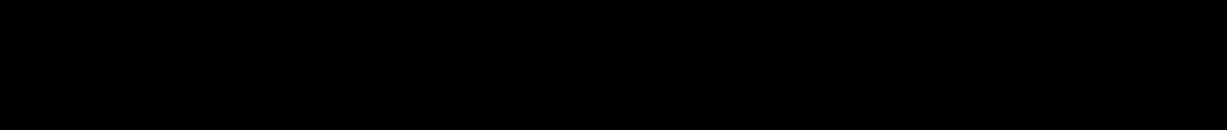
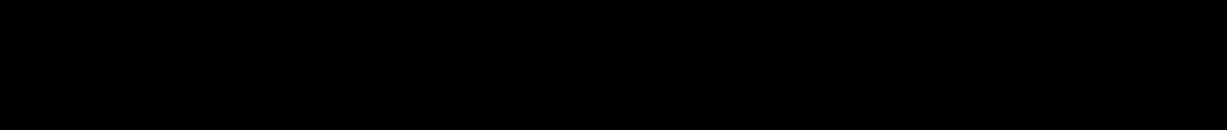
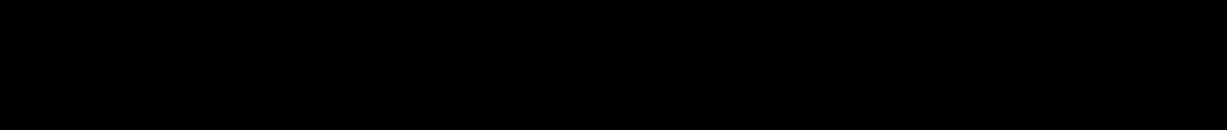

## 1. Data source and raw data

The data come from the official [NESO Historic Demand Data](https://www.neso.energy/data-portal/historic-demand-data) portal. NESO also provides a [2025 data page and field descriptions](https://www.neso.energy/data-portal/historic-demand-data/historic_demand_data_2025). The project uses the annual CSV files for 2021–2025.

The dataset is maintained on NESO's live data portal. The files used in this project contain real historical operational records, rather than synthetic or pre-cleaned Kaggle data. The annual files also contain practical issues: date formats differ, the
`SCOTTISH_TRANSFER` column is absent in 2021–2022, and daylight-saving-time days can contain 46 or 50 settlement periods.
NESO may revise historical values after publication.

Each row represents one half-hour settlement period. The main raw variables are:

| Variable | Meaning |
|---|---|
| `SETTLEMENT_DATE` | Date of the observation |
| `SETTLEMENT_PERIOD` | Half-hour period within the settlement day |
| `ND` | Great Britain National Demand in MW; the prediction target |
| `TSD` | Transmission System Demand in MW |
| `ENGLAND_WALES_DEMAND` | Demand for England and Wales in MW |
| `EMBEDDED_WIND_*`, `EMBEDDED_SOLAR_*` | Estimated embedded generation and capacity |
| `PUMP_STORAGE_PUMPING` | Electricity used for pumped-storage pumping |
| `SCOTTISH_TRANSFER`, `*_FLOW` | Internal transfer and interconnector flows |

Although the raw files contain many variables, the final model uses only information available at the forecast origin: lagged demand, calendar variables and the England and Wales bank-holiday flag.

In [1]:
from pathlib import Path
import warnings

import matplotlib
if "get_ipython" not in globals():
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")

def find_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "results" / "tables").exists() and (candidate / "src").exists():
            return candidate
    raise FileNotFoundError("Run the notebook from inside the project directory.")

PROJECT_ROOT = find_project_root(Path.cwd().resolve())
TABLES_DIR = PROJECT_ROOT / "results" / "tables"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
RAW_DATA_FILE = PROJECT_ROOT / "data" / "raw" / "demanddata_2025.csv"
CLEAN_DATA_FILE = PROJECT_ROOT / "data" / "processed" / "clean_demand_data_2021_2025.csv"

def load_table(filename: str) -> pd.DataFrame:
    path = TABLES_DIR / filename
    if not path.exists():
        raise FileNotFoundError(f"Missing {path}. Run python run_pipeline.py first.")
    return pd.read_csv(path)

def print_table(frame: pd.DataFrame, rows: int | None = None) -> None:
    output = frame if rows is None else frame.head(rows)
    print(output.to_string(index=False))

def show_saved_figure(filename: str, title: str | None = None) -> None:
    path = FIGURES_DIR / filename
    if not path.exists():
        raise FileNotFoundError(f"Missing {path}. Run python run_pipeline.py first.")
    image = plt.imread(path)
    figure, axis = plt.subplots(figsize=(12, 7))
    axis.imshow(image)
    axis.axis("off")
    if title:
        axis.set_title(title)
    plt.tight_layout()
    if "get_ipython" in globals():
        plt.show()
    else:
        figure.canvas.draw()
    plt.close(figure)

print(f"Project root: {PROJECT_ROOT}")

Project root: C:\Users\Lenovo\Documents\COMP702_Electricity_Load_Forecasting


### Raw table and coverage

The next cell shows the first five rows of the downloaded 2025 file before cleaning. It then checks the number of half-hour observations in the complete cleaned series. The 2024 count is higher because 2024 was a leap year.

In [2]:
for required_file in [RAW_DATA_FILE, CLEAN_DATA_FILE]:
    if not required_file.exists():
        raise FileNotFoundError(f"Missing {required_file}. Run python run_pipeline.py first.")

raw_2025 = pd.read_csv(RAW_DATA_FILE)
print(f"Raw 2025 file: {raw_2025.shape[0]:,} rows and {raw_2025.shape[1]} columns")
if "get_ipython" in globals():
    display(raw_2025.head())
else:
    print_table(raw_2025, rows=5)

demand = pd.read_csv(CLEAN_DATA_FILE, usecols=["DATETIME", "ND"])
demand["DATETIME"] = pd.to_datetime(demand["DATETIME"], utc=True).dt.tz_convert("Europe/London")
demand["year"] = demand["DATETIME"].dt.year
coverage = demand.groupby("year").agg(
    Rows=("ND", "size"),
    Start=("DATETIME", "min"),
    End=("DATETIME", "max"),
    Mean_MW=("ND", "mean"),
).reset_index()
coverage["Missing_ND"] = demand.groupby("year")["ND"].apply(lambda values: int(values.isna().sum())).to_numpy()
print_table(coverage)
print(f"\nTotal observations: {len(demand):,}")

Raw 2025 file: 17,520 rows and 22 columns


,SETTLEMENT_DATE,SETTLEMENT_PERIOD,ND,TSD,ENGLAND_WALES_DEMAND,EMBEDDED_WIND_GENERATION,EMBEDDED_WIND_CAPACITY,EMBEDDED_SOLAR_GENERATION,EMBEDDED_SOLAR_CAPACITY,NON_BM_STOR,PUMP_STORAGE_PUMPING,SCOTTISH_TRANSFER,IFA_FLOW,IFA2_FLOW,BRITNED_FLOW,MOYLE_FLOW,EAST_WEST_FLOW,NEMO_FLOW,NSL_FLOW,ELECLINK_FLOW,VIKING_FLOW,GREENLINK_FLOW
0,2025-01-01,1,21036,26215,19918,5405,6606,0,19270,0,859,6353,-1518,-1026,1,-232,-386,-558,96,0,241,0
1,2025-01-01,2,21222,26063,20167,5358,6606,0,19270,0,735,6333,-1513,-1023,1,-124,-282,-564,51,0,262,0
2,2025-01-01,3,21385,25734,20328,5237,6606,0,19270,0,691,6380,-1428,-922,1,-119,-384,-205,62,0,414,0
3,2025-01-01,4,20473,24988,19460,5115,6606,0,19270,0,931,6250,-1423,-915,0,-119,-334,-193,37,0,423,0
4,2025-01-01,5,19634,24912,18654,5080,6606,0,19270,0,854,6142,-1539,-899,0,-119,-363,-622,-282,0,288,0


 year  Rows                     Start                       End     Mean_MW  Missing_ND
 2021 17520 2021-01-01 00:00:00+00:00 2021-12-31 23:30:00+00:00 28,345.2946           0
 2022 17520 2022-01-01 00:00:00+00:00 2022-12-31 23:30:00+00:00 26,622.2890           0
 2023 17520 2023-01-01 00:00:00+00:00 2023-12-31 23:30:00+00:00 26,051.7452           0
 2024 17568 2024-01-01 00:00:00+00:00 2024-12-31 23:30:00+00:00 26,286.7630           0
 2025 17520 2025-01-01 00:00:00+00:00 2025-12-31 23:30:00+00:00 26,158.0726           0

Total observations: 87,648


## 2. Experimental design

| Decision | Method |
|---|---|
| Forecast horizon | 48 half-hour settlement periods (24 hours) |
| Feature selection | Train on 2021–2022; compare feature sets on 2023 |
| Model tuning | Train on 2021–2023; validate on 2024 |
| Final evaluation | Refit on 2021–2024; evaluate on 2025 after all choices were fixed |
| Metrics | RMSE and MAE in MW; MAPE in percent |
| Preventing leakage | Split by time and use only information available before each target |

The 2025 targets were kept separate until all feature and parameter choices were fixed. They were then used for final evaluation and stability analysis. No modelling choice was changed in response to the 2025 results.

For actual demand $y_t$, forecast $\hat{y}_t$, and $n$ test observations, the three error measures are:

$$\mathrm{MAE}=\frac{1}{n}\sum_{t=1}^{n}|y_t-\hat{y}_t|,$$

$$\mathrm{RMSE}=\sqrt{\frac{1}{n}\sum_{t=1}^{n}(y_t-\hat{y}_t)^2},$$

$$\mathrm{MAPE}=\frac{100}{n}\sum_{t=1}^{n}\left|\frac{y_t-\hat{y}_t}{y_t}\right|.$$

MAE is the average absolute error in MW. RMSE is also in MW but gives more weight to large errors. MAPE expresses the average error as a percentage of demand. Lower values are better.

## 3. Descriptive demand analysis

**Why:** Annual and monthly averages show whether demand changes over years and seasons before models are compared.

**Method:** For year $y$, I take the arithmetic mean of every half-hourly `ND` observation in that year:

$$\bar{D}_y=\frac{1}{N_y}\sum_{t\in\mathcal{T}_y}D_t,$$

where $D_t$ is demand in MW, $\mathcal{T}_y$ is the set of half-hours in year $y$, and $N_y$ is their number. Each half-hour has equal weight; I do not average daily means and then average those again.

The next code cell implements this formula with `groupby("year")["ND"].agg(...)`; the reusable implementation is in [`src/descriptive_statistics.py`](../src/descriptive_statistics.py). For the monthly plot, I group all 2021–2024 observations by month number—all Januaries together, all Februaries together, and so on—and average the half-hourly values directly. Only 2021–2024 are used here so the 2025 test targets cannot influence model development.

Annual mean calculated from the formula above
 year  count        mean
 2021  17520 28,345.2946
 2022  17520 26,622.2890
 2023  17520 26,051.7452
 2024  17568 26,286.7630

Monthly demand summary
 month  count        mean        std      median         q25         q75         min         max
     1   5952 32,263.9827 6,805.4842 32,766.5000 26,386.5000 38,018.5000 16,456.0000 46,433.0000
     2   5424 30,333.2378 5,928.1561 30,793.5000 24,940.2500 35,008.7500 17,697.0000 46,148.0000
     3   5944 28,944.3299 5,426.7889 28,894.0000 24,246.5000 33,197.2500 17,594.0000 42,475.0000
     4   5760 26,062.3095 4,362.6122 25,910.0000 22,392.2500 29,792.2500 15,871.0000 37,842.0000
     5   5952 24,082.3379 4,101.6927 24,087.0000 20,501.5000 27,340.2500 14,805.0000 34,246.0000
     6   5760 23,091.3568 3,776.2322 23,167.5000 19,808.5000 26,074.0000 14,879.0000 32,838.0000
     7   5952 23,250.2226 3,775.6476 23,625.0000 19,912.0000 26,327.5000 13,601.0000 31,791.0000
     8   5952 23,007.7745 3,8

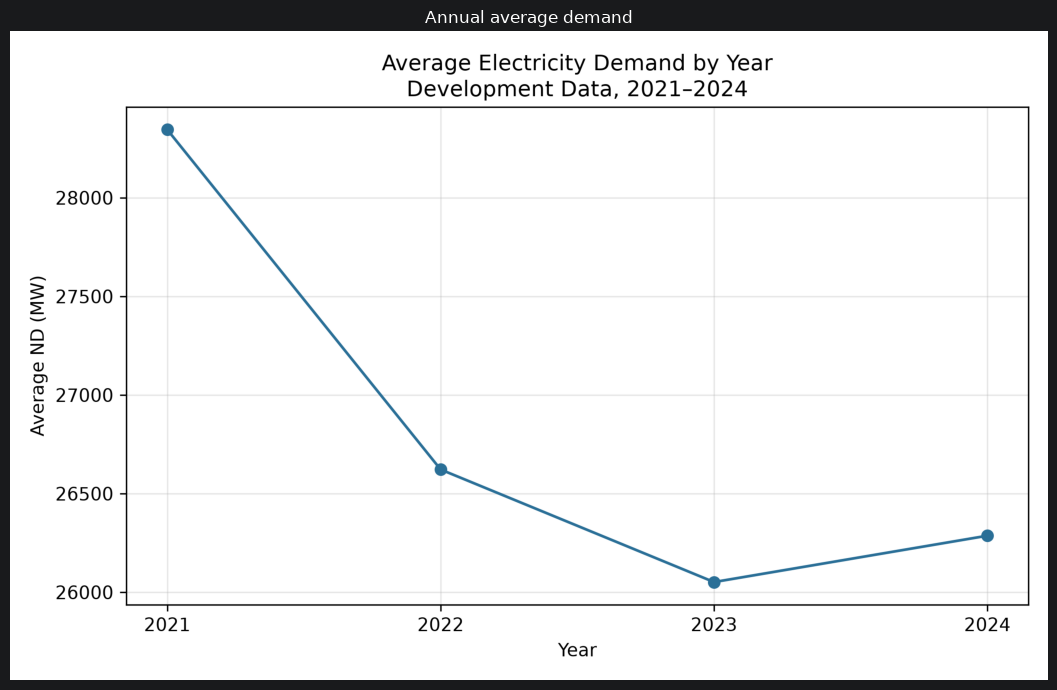

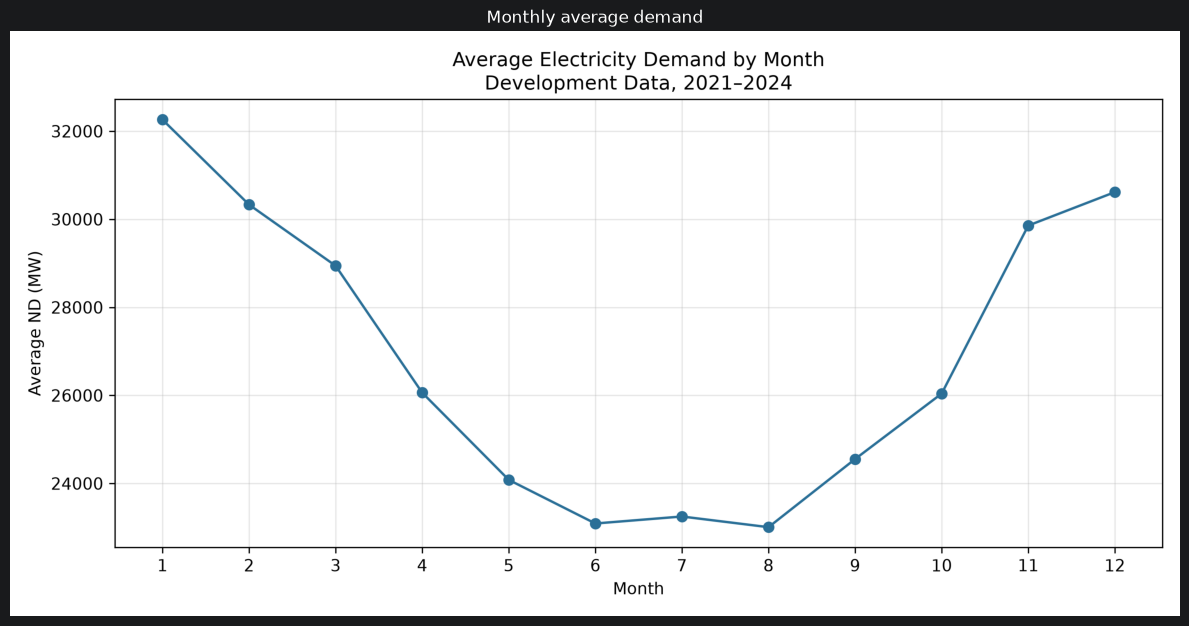

In [3]:
development_demand = demand[demand["year"].between(2021, 2024)].copy()
yearly_demand = (
    development_demand.groupby("year", as_index=False)["ND"]
    .agg(count="count", mean="mean")
)
monthly_demand = load_table("monthly_average_demand.csv")
print("Annual mean calculated from the formula above")
print_table(yearly_demand)
print("\nMonthly demand summary")
print_table(monthly_demand)
show_saved_figure("average_demand_by_year.png", "Annual average demand")
show_saved_figure("average_demand_by_month.png", "Monthly average demand")

### Descriptive results and conclusion

**Annual plot:** Mean demand fell from 28,345 MW in 2021 to 26,052 MW in 2023, then rose slightly to 26,287 MW in 2024. This shows that the overall demand level was not completely stable, but the plot does not identify the cause.

**Monthly plot:** Across 2021–2024, January had the highest mean demand (32,264 MW) and August the lowest (23,008 MW). This seasonal pattern supports testing calendar features in the forecasting models.

## 4. Persistence and ARIMA baselines

**Why:** A machine-learning model is useful only if it improves on simple forecasts.

**Method:** Persistence is a simple forecast that copies an earlier observed value. Daily persistence uses demand 48 elapsed half-hours earlier (`lag_48`), while weekly persistence uses demand 336 elapsed half-hours earlier (`lag_336`).

ARIMA predicts future demand from earlier values and forecast errors. In the ARIMA$(p,1,0)$ models used here, the first difference $\Delta D_t=D_t-D_{t-1}$ is modelled as

$$\Delta D_t=c+\sum_{i=1}^{p}\phi_i\Delta D_{t-i}+\varepsilon_t.$$

Here, $c$ is a constant, $\phi_i$ weights earlier changes, and $\varepsilon_t$ is the unexplained error. The order $p$ was selected on 2024. The selected model was then refitted on 2021–2024 and tested on 2025. Every ARIMA prediction follows a 48-step path, so it has the same 24-hour information limit as the other models.

Final 2025 baseline performance
           Model Selected_Order       RMSE        MAE    MAPE
 lag_48_baseline Not applicable 2,573.7543 1,846.4510  7.3570
lag_336_baseline Not applicable 2,921.7268 2,185.8224  8.4661
           ARIMA   ARIMA(3,1,0) 3,541.7491 2,732.0930 10.7672

ARIMA order selection on 2024
       Order       RMSE        MAE    MAPE  Selected
ARIMA(3,1,0) 3,525.1854 2,710.2954 10.5417      True
ARIMA(2,1,0) 5,404.3663 4,127.1230 16.0020     False
ARIMA(1,1,0) 6,444.2411 4,895.8412 18.9634     False


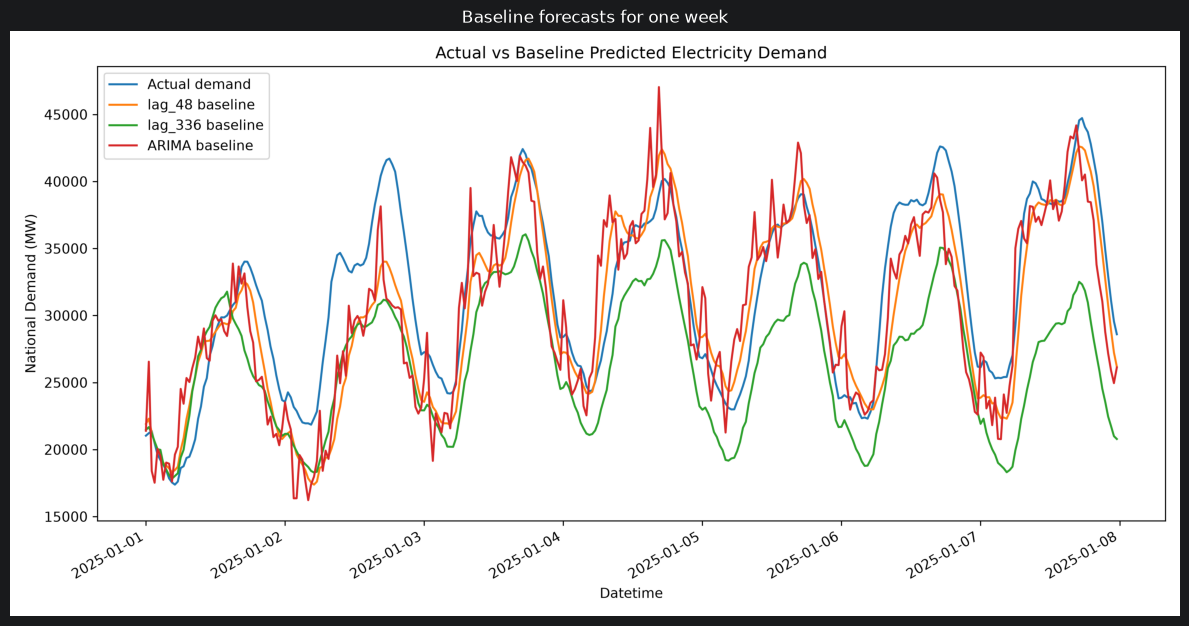

In [4]:
baseline_results = load_table("baseline_results.csv").sort_values("MAPE")
arima_validation = load_table("arima_validation_results.csv").sort_values("MAPE")
print("Final 2025 baseline performance")
print_table(baseline_results[["Model", "Selected_Order", "RMSE", "MAE", "MAPE"]])
print("\nARIMA order selection on 2024")
print_table(arima_validation[["Order", "RMSE", "MAE", "MAPE", "Selected"]])
show_saved_figure("actual_vs_baseline_predictions_one_week.png", "Baseline forecasts for one week")

### Baseline result and conclusion

Daily persistence was the best simple baseline on 2025, with MAPE 7.357%. Weekly persistence reached 8.466%, while the selected ARIMA(3,1,0) reached 10.767%. For the displayed week, daily persistence follows the demand cycle more closely, weekly persistence is too low for much of the week, and ARIMA is erratic. Together with its higher annual MAPE, this shows that the non-seasonal ARIMA model used here did not represent the daily and weekly pattern well enough.

## 5. Feature-ablation experiment

**Why:** This experiment checks which feature groups improve prediction instead of assuming that more inputs are always better.

**Method:** I used **leave-one-group-out** ablation, not leave-one-feature-out. Starting from a fixed LightGBM reference, I removed one pre-defined group at a time and measured

$$\Delta\mathrm{MAPE}_g=\mathrm{MAPE}_{\text{without group }g}-\mathrm{MAPE}_{\text{reference}}.$$

A positive value means that removing group $g$ made the forecast worse. The model parameters stayed fixed, training used 2021–2022, and comparison used 2023. Because errors on nearby days may be related, I calculated 95% uncertainty intervals by resampling seven-day blocks rather than individual days. Holiday dates were safe to use because they are known in advance. Realised future weather was not used because that would leak information unless archived forecasts were available.

Formal ablation and refinement on 2023
                           Experiment_Type                      Feature_Set  Feature_Count   MAPE  MAPE_CI_Lower  MAPE_CI_Upper  Selected
                                 Reference           All candidate features             11 5.0566         4.6578         5.3838     False
                       Leave-one-group-out                Without daily lag             10 5.8831         5.4309         6.2933     False
                       Leave-one-group-out               Without weekly lag             10 5.0689         4.6407         5.4181     False
Leave-one-group-out / candidate refinement Selected + both GB holiday flags              9 4.9206         4.5859         5.2185     False
                       Leave-one-group-out        Without calendar features              6 5.9381         5.5402         6.3002     False
                       Leave-one-group-out    Without England/Wales holiday             10 5.1114         4.7022         5.4619     F

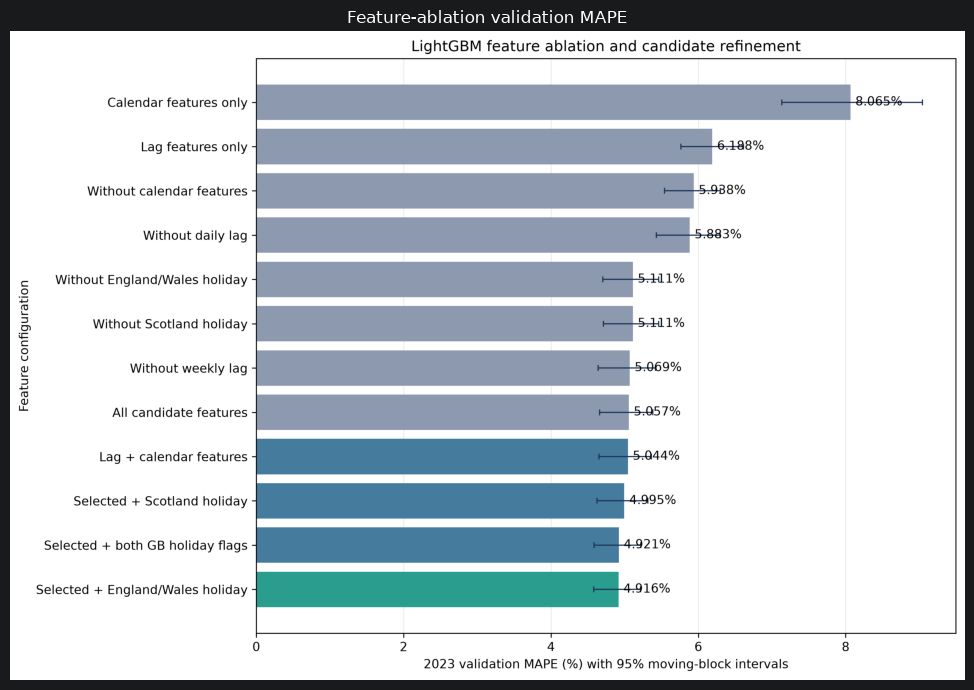

In [5]:
ablation = load_table("feature_ablation_results.csv").sort_values("Experiment_Order")
selected_ablation = ablation[ablation["Selected"].astype(str).str.lower().eq("true")]
candidate_ablation = ablation[ablation["Eligible_For_Selection"].astype(str).str.lower().eq("true")].sort_values("Candidate_Rank")
print("Formal ablation and refinement on 2023")
print_table(ablation[["Experiment_Type", "Feature_Set", "Feature_Count", "MAPE", "MAPE_CI_Lower", "MAPE_CI_Upper", "Selected"]])
print("\nCandidate ranking and paired uncertainty")
print_table(candidate_ablation[["Candidate_Rank", "Feature_Set", "Feature_Count", "MAPE", "Delta_MAPE_vs_Best_Candidate", "Delta_vs_Best_CI_Lower", "Delta_vs_Best_CI_Upper", "Statistically_Tied_With_Best", "Selected"]])
print("\nSelected features")
print(selected_ablation["Features"].iloc[0])
print("Selection rationale")
print(selected_ablation["Selection_Rationale"].iloc[0])
show_saved_figure("feature_ablation_mape.png", "Feature-ablation validation MAPE")

### Feature-ablation result and conclusion

Removing the calendar group raised MAPE from 5.057% to 5.938%, an increase of 0.882 percentage points. Removing the daily lag raised it to 5.883%, an increase of 0.827 points. The selected eight-feature set used both demand lags, five calendar variables, and the England and Wales bank-holiday flag; it achieved 4.916% MAPE. Adding the Scotland holiday flag produced a nine-feature version with 4.921% MAPE, and its paired difference interval included zero. I therefore kept the smaller eight-feature set.

## 6. Machine-learning model validation and final test

**Why:** The main comparison asks whether nonlinear models improve 2025 day-ahead accuracy.

**Models:** Ridge Regression fits one linear equation and penalises very large coefficients to reduce overfitting. Random Forest fits many decision trees to resampled data and averages their predictions. XGBoost and LightGBM build trees in sequence, with each new tree trying to correct earlier errors.

**Method:** Hyperparameters were selected on 2024. Each selected model was refitted on 2021–2024 and evaluated on 2025. I resampled daily errors in seven-day blocks to calculate a 95% interval for each MAPE difference. If the interval includes zero, the results do not show a clear difference between the models.

Selected configurations and 2024 validation results
           Model  Candidate                              Parameters       RMSE        MAE   MAPE
         XGBoost          2   {"max_depth": 4, "n_estimators": 400} 1,680.6485 1,248.2540 4.8989
        LightGBM          1 {"n_estimators": 200, "num_leaves": 31} 1,688.5146 1,256.6611 4.9263
   Random Forest          4  {"max_depth": 20, "n_estimators": 200} 1,804.1640 1,328.1809 5.2098
Ridge Regression          1                  {"ridge__alpha": 0.01} 1,964.1095 1,469.2633 5.7065

Final 2025 ML results
           Model       RMSE        MAE   MAPE  Validation_MAPE
        LightGBM 1,803.2941 1,318.7473 5.3371           4.9263
         XGBoost 1,797.2696 1,335.0322 5.3869           4.8989
   Random Forest 1,859.7471 1,362.0212 5.4959           5.2098
Ridge Regression 2,054.5850 1,534.7377 6.0494           5.7065

Paired 7-day moving-block bootstrap comparisons
      Model_A          Model_B  Mean_Daily_MAPE_Difference_A_Minus_B  Differ

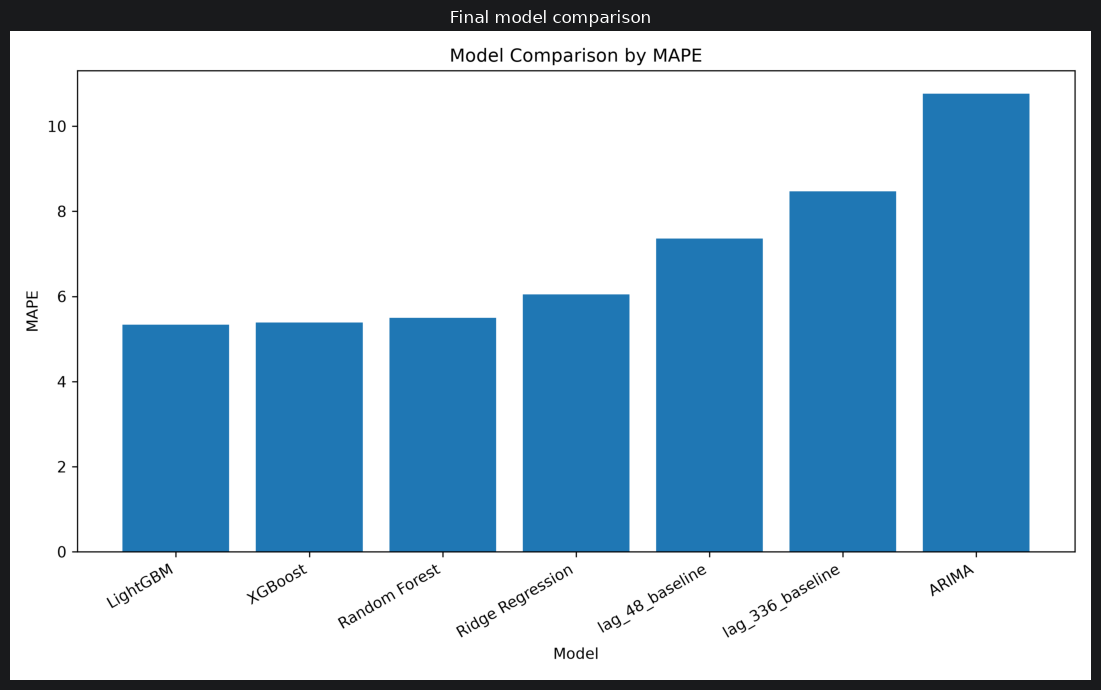

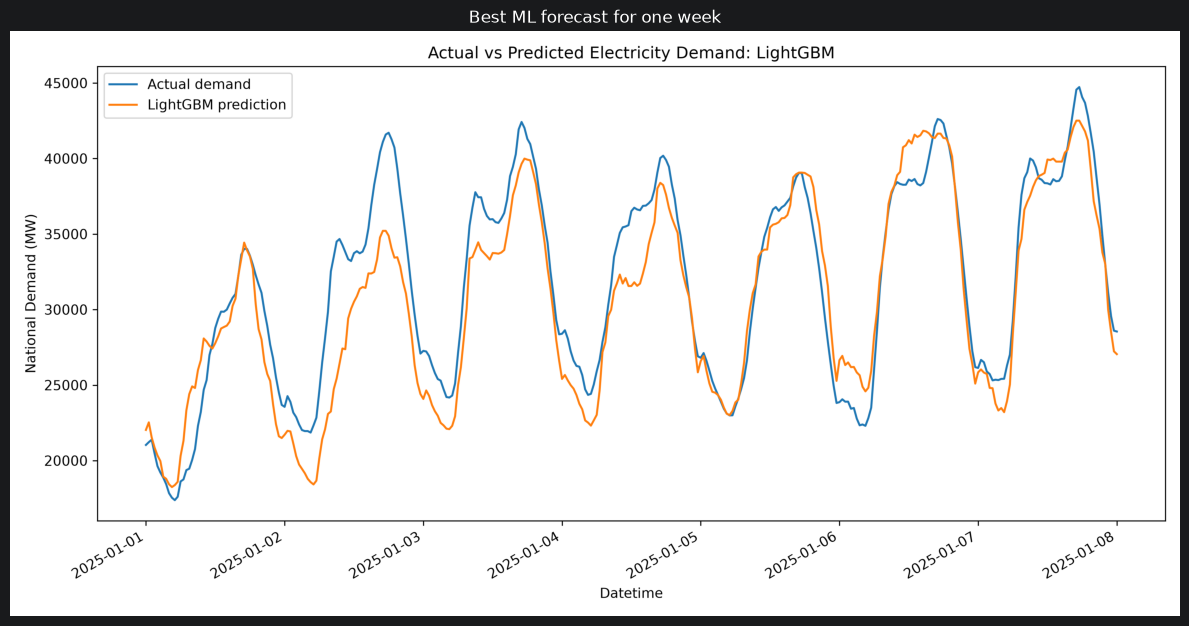

In [6]:
ml_validation = load_table("ml_validation_results.csv")
ml_results = load_table("ml_model_results.csv").sort_values("MAPE")
ml_comparisons = load_table("ml_model_comparison_bootstrap.csv")
selected_validation = ml_validation[ml_validation["Selected"].astype(str).str.lower().eq("true")].sort_values("MAPE")
print("Selected configurations and 2024 validation results")
print_table(selected_validation[["Model", "Candidate", "Parameters", "RMSE", "MAE", "MAPE"]])
print("\nFinal 2025 ML results")
print_table(ml_results[["Model", "RMSE", "MAE", "MAPE", "Validation_MAPE"]])
print("\nPaired 7-day moving-block bootstrap comparisons")
print_table(ml_comparisons[["Model_A", "Model_B", "Mean_Daily_MAPE_Difference_A_Minus_B", "Difference_CI_Lower", "Difference_CI_Upper", "CI_Includes_Zero"]])
show_saved_figure("model_comparison_mape.png", "Final model comparison")
show_saved_figure("actual_vs_predicted_lightgbm_one_week.png", "Best ML forecast for one week")

### Final-model result and conclusion

**Model-comparison plot:** LightGBM had the lowest 2025 MAPE point estimate (5.337%), followed by XGBoost (5.387%), Random Forest (5.496%), and Ridge Regression (6.049%). LightGBM reduced MAPE by about 27.5% relative to daily persistence. The LightGBM–XGBoost interval was [-0.169, 0.042] percentage points and included zero, so the results do not show a clear performance difference between them.

**One-week forecast plot:** LightGBM follows the repeated daily rises and falls but underestimates several peaks.

## 7. Feature importance

**Why:** Feature importance helps check what information a fitted tree model used. It does not prove that a variable causes demand to change.

**Method:** Importance values are normalised within each model for the comparison table because the libraries use different raw scales. The LightGBM plot shows the within-model importance ranking. These values should be treated as model diagnostics rather than causal effects.

Top five features per tree model
        Model                       Feature  Relative_Importance
     LightGBM                   day_of_year               0.3127
     LightGBM                   day_of_week               0.2118
     LightGBM             settlement_period               0.1602
     LightGBM                        lag_48               0.1408
     LightGBM                       lag_336               0.1253
Random Forest                        lag_48               0.5461
Random Forest                       lag_336               0.3639
Random Forest                   day_of_week               0.0293
Random Forest                   day_of_year               0.0266
Random Forest             settlement_period               0.0215
      XGBoost                        lag_48               0.5224
      XGBoost                       lag_336               0.3739
      XGBoost                    is_weekend               0.0279
      XGBoost                   day_of_week              

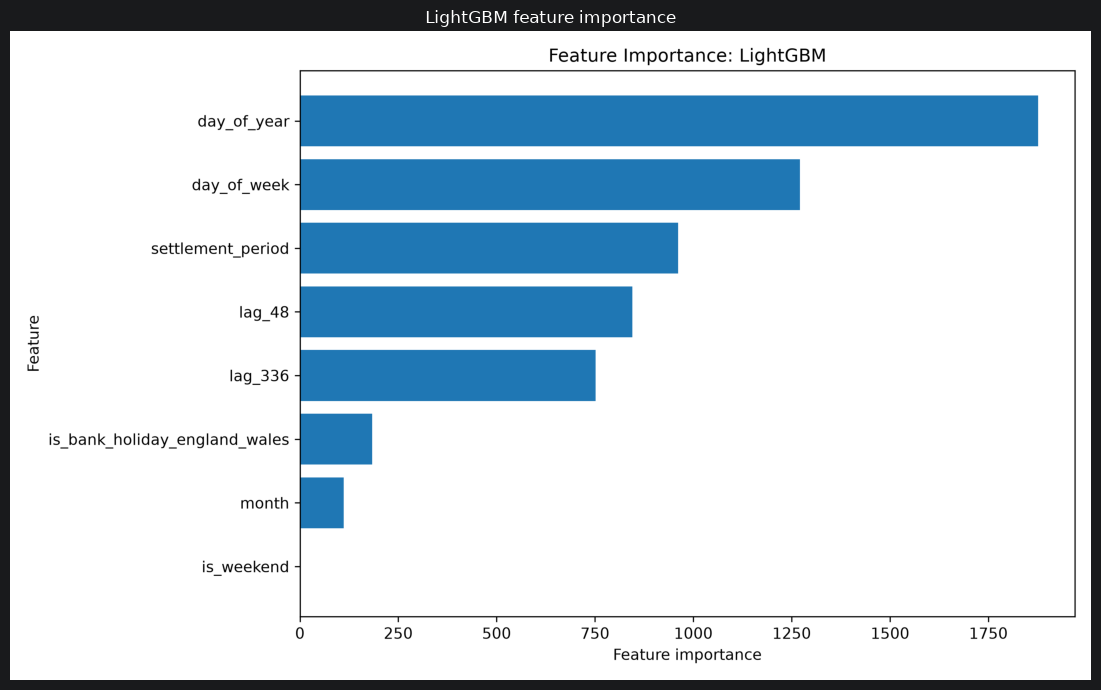

In [7]:
feature_importance = load_table("feature_importance.csv")
feature_importance["Relative_Importance"] = feature_importance.groupby("Model")["Importance"].transform(
    lambda values: values / values.sum() if values.sum() else values
)
top_features = (
    feature_importance.sort_values(["Model", "Relative_Importance"], ascending=[True, False])
    .groupby("Model", as_index=False)
    .head(5)
)
print("Top five features per tree model")
print_table(top_features[["Model", "Feature", "Relative_Importance"]])
show_saved_figure("feature_importance_lightgbm.png", "LightGBM feature importance")

### Feature-importance result and conclusion

For LightGBM, `day_of_year` had the largest relative importance, followed by `day_of_week`, `settlement_period`, `lag_48`, and `lag_336`. This is consistent with strong seasonal, weekly, intraday, and recent-demand patterns. The result explains model behaviour but does not show that these variables cause demand.

## 8. Distribution-drift analysis

**Why:** A model can become less reliable if the demand or input distributions change after training.

**Method:** The 2021–2023 training distribution is compared with 2024 and 2025. PSI compares how observations are distributed across the same bins in two periods; zero means no change. I label values below 0.10 as small, values from 0.10 to 0.25 as moderate, and values of at least 0.25 as large. KS reports the largest gap between two continuous distributions, while normalised Wasserstein distance describes their overall separation. These are descriptive checks, not proof that the relationship between the inputs and demand has changed. Each comparison uses complete local calendar days.

Drift summary
       Comparison    Comparison_Type  Variables_Monitored  Stable_Variables  Moderate_Shift_Variables  Large_Shift_Variables  Maximum_PSI Largest_Shift_Variable
2021-2023 -> 2024 Training reference                    9                 9                         0                      0       0.0225                lag_336
2021-2023 -> 2025 Training reference                    9                 9                         0                      0       0.0474                lag_336
     2021 -> 2022      Adjacent year                    9                 9                         0                      0       0.0985                 lag_48
     2022 -> 2023      Adjacent year                    9                 9                         0                      0       0.0210                lag_336
     2023 -> 2024      Adjacent year                    9                 9                         0                      0       0.0112                 lag_48
     2024 -> 2025   

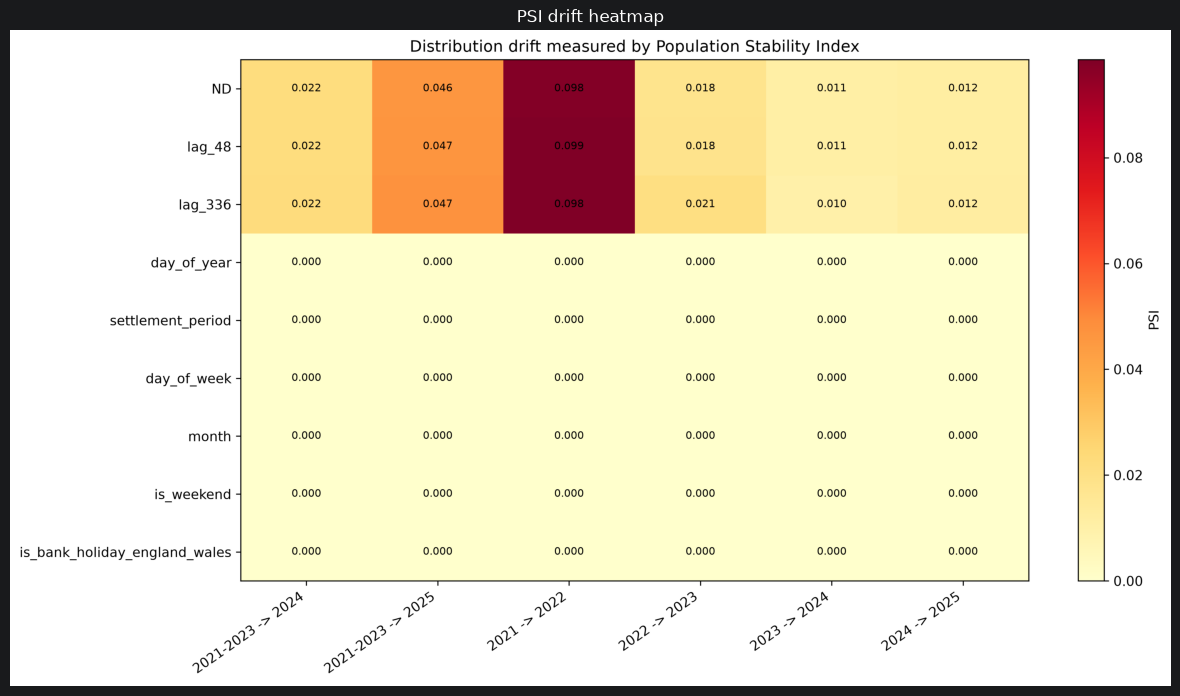

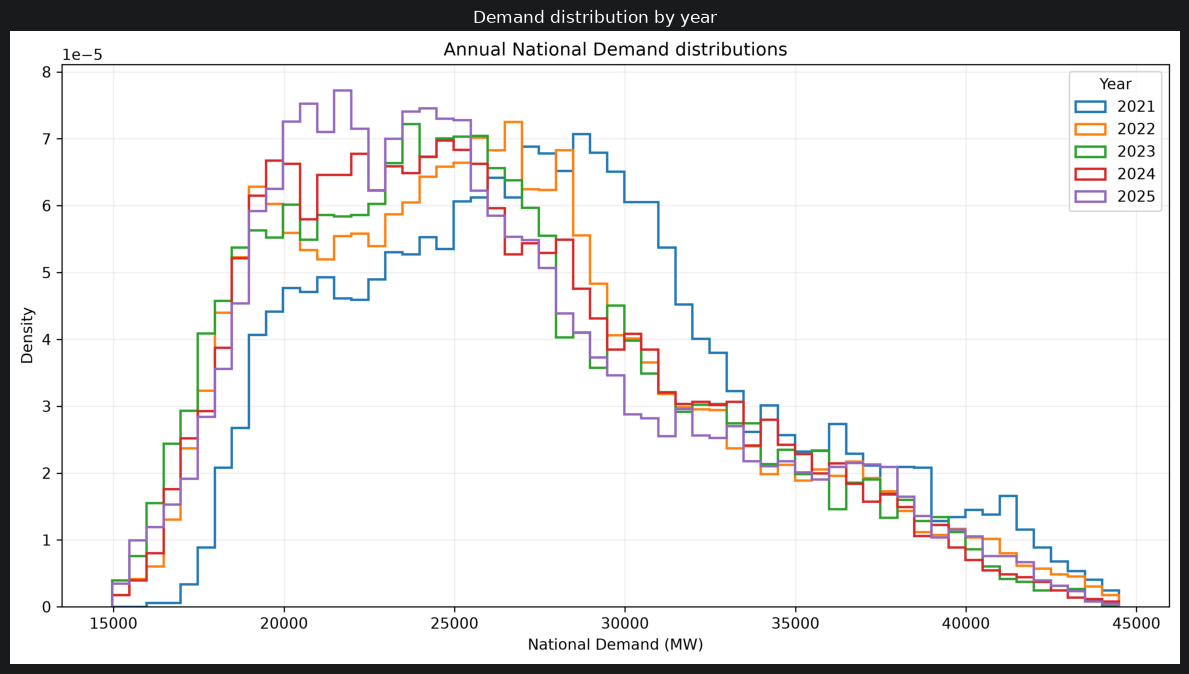

In [8]:
drift_results = load_table("distribution_drift_results.csv")
drift_summary = load_table("distribution_drift_summary.csv")
training_drift = drift_results[drift_results["Comparison_Type"].eq("Training reference")].copy()
demand_drift = training_drift[training_drift["Variable"].eq("ND")][[
    "Comparison", "Reference_Mean", "Current_Mean", "Mean_Change_Percent",
    "PSI", "PSI_Severity", "KS_Statistic", "Normalised_Wasserstein",
]]
print("Drift summary")
print_table(drift_summary)
print("\nTarget-demand drift against training reference")
print_table(demand_drift)
show_saved_figure("distribution_drift_psi_heatmap.png", "PSI drift heatmap")
show_saved_figure("nd_distribution_by_year.png", "Demand distribution by year")

### Distribution-drift result and conclusion

**PSI heatmap:** All nine monitored variables remained below PSI 0.10; the largest 2025 value was 0.0474.

**Yearly demand distributions:** Mean `ND` in 2025 was 3.37% lower than the 2021–2023 reference. Together, the plots show a small measurable shift, not severe distribution drift. Distribution change alone does not prove that the forecasting relationship changed.

## 9. Fixed-origin degradation check

**Why:** This experiment asks whether a model becomes less accurate when its learned parameters are not refreshed.

**Method:** Each model is trained once on 2021–2023 and then kept unchanged while being evaluated on 2024 and 2025. Each daily forecast can still use the latest observed demand lags. This tests whether an unchanged model becomes less accurate; it is not one two-year forecast made at the end of 2023. The change interval is calculated by resampling seven-day blocks of daily errors.

Frozen-model change from 2024 to 2025
           Model                    Model_Type  First_MAPE  Last_MAPE  Absolute_MAPE_Change  Relative_MAPE_Change_Percent  Change_CI_Lower  Change_CI_Upper  Change_CI_Includes_Zero                Observed_Change                                     Evidence_Scope
         XGBoost Frozen machine-learning model      4.9165     5.5036                0.5871                       11.9406           0.1409           1.0448                    False Higher error in last test year Two annual evaluations only; not a long-term trend
        LightGBM Frozen machine-learning model      4.9263     5.5034                0.5771                       11.7150           0.1253           1.0599                    False Higher error in last test year Two annual evaluations only; not a long-term trend
lag_336_baseline          Persistence baseline      7.7403     8.4661                0.7258                        9.3767          -0.0277           1.6066                  

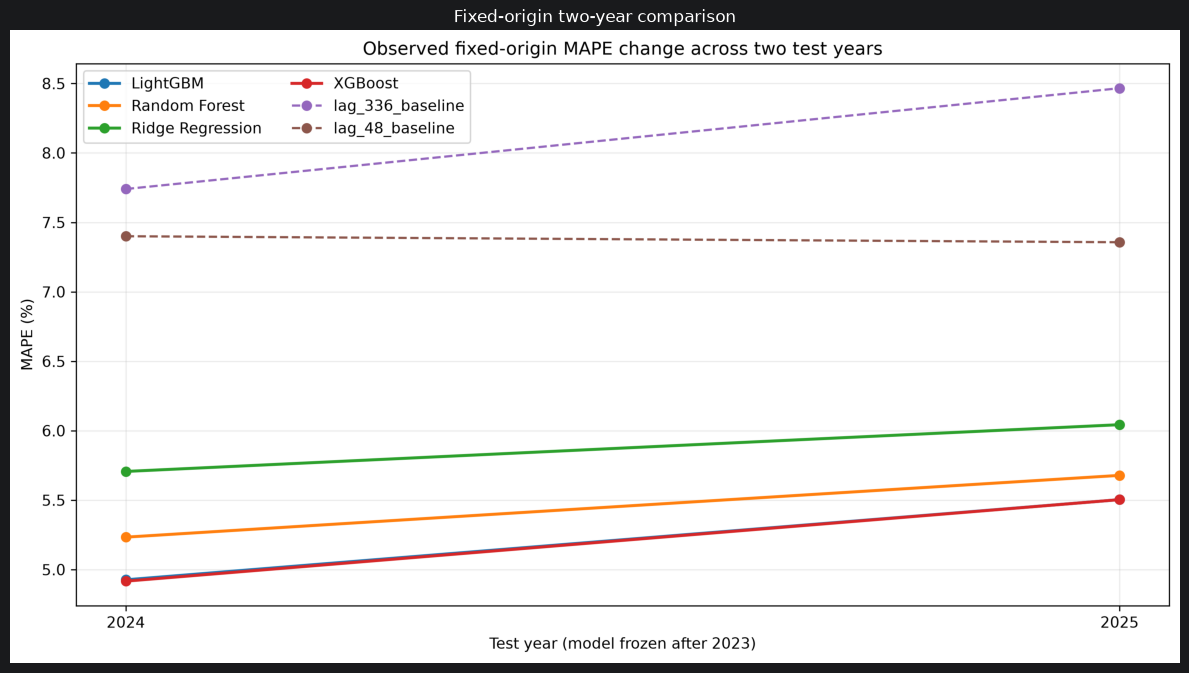

In [9]:
fixed_origin = load_table("fixed_origin_degradation_summary.csv").sort_values(
    "Relative_MAPE_Change_Percent", ascending=False
)
print("Frozen-model change from 2024 to 2025")
print_table(fixed_origin[[
    "Model", "Model_Type", "First_MAPE", "Last_MAPE",
    "Absolute_MAPE_Change", "Relative_MAPE_Change_Percent",
    "Change_CI_Lower", "Change_CI_Upper", "Change_CI_Includes_Zero",
    "Observed_Change", "Evidence_Scope",
]])
show_saved_figure("fixed_origin_mape_degradation.png", "Fixed-origin two-year comparison")

### Fixed-origin result and conclusion

From 2024 to 2025, frozen-model MAPE increased by 11.94% for XGBoost, 11.72% for LightGBM, and 8.50% for Random Forest; their change intervals excluded zero. Ridge increased by 5.90%, but its interval included zero. Daily persistence stayed approximately stable. This suggests that 2025 was harder for the frozen nonlinear models, but two annual evaluations are not enough to claim a long-term trend.

## 10. Monthly, seasonal, and rolling-origin robustness

**Why:** One annual error value can hide weak months, and a single test year cannot show whether model rankings are repeatable.

**Method:** I report MAPE by month and season, then repeat the same chronological fitting and testing pattern for several test years. For the rolling-year check, each model uses the same pre-specified base configuration in every test year and is trained only on earlier data. This checks year-to-year stability, so its values are not always identical to the final tuned 2025 comparison.

Best and worst months for LightGBM
 month    Model       RMSE        MAE   MAPE  Rows
     1 LightGBM 1,929.5582 1,444.5448 4.4536  1488
    10 LightGBM 1,481.2763 1,162.3693 4.5421  1490
     2 LightGBM 1,856.8697 1,427.3502 4.6814  1344
     3 LightGBM 2,114.4793 1,579.0308 6.1043  1486
     6 LightGBM 1,743.3606 1,350.9413 6.3993  1440
     4 LightGBM 2,058.6073 1,419.5870 6.4754  1440

Seasonal MAPE
Model   ARIMA(3,1,0) selected  LightGBM  Random Forest  Ridge Regression  XGBoost  lag_336_baseline  lag_48_baseline
season                                                                                                              
Autumn                10.8576    5.0034         5.2063            5.8775   4.9910            7.7824           7.1321
Spring                11.6746    6.1771         5.9680            6.6385   6.2274            9.1117           8.2208
Summer                10.6213    5.5211         5.8681            5.9689   5.5407            7.9008           7.8022
Winter  

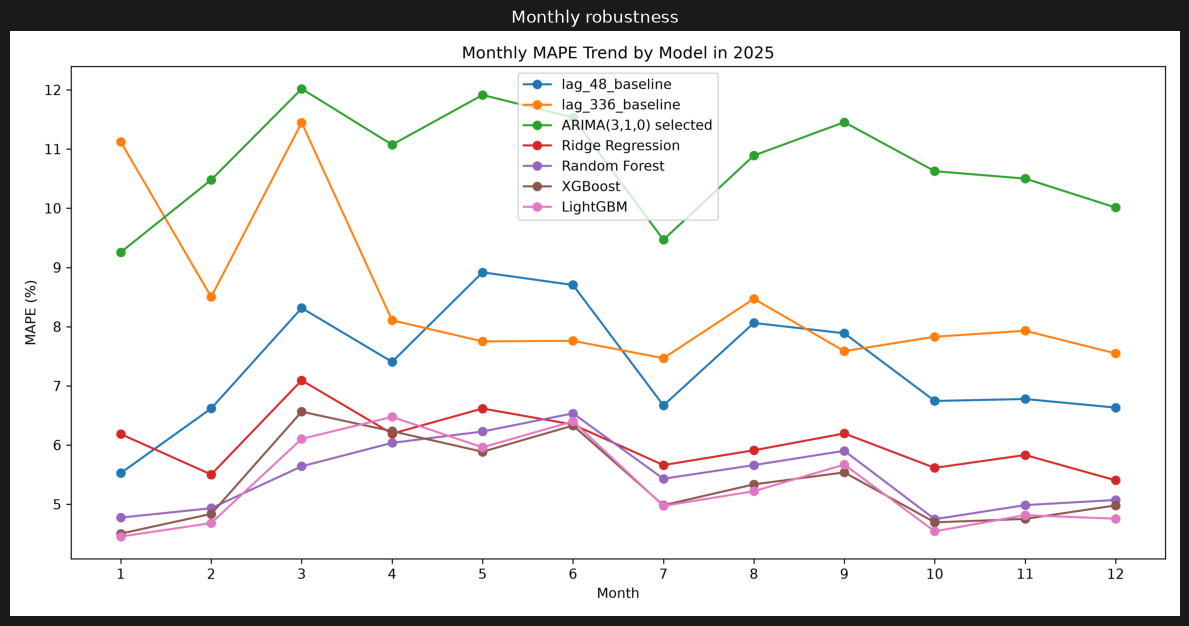

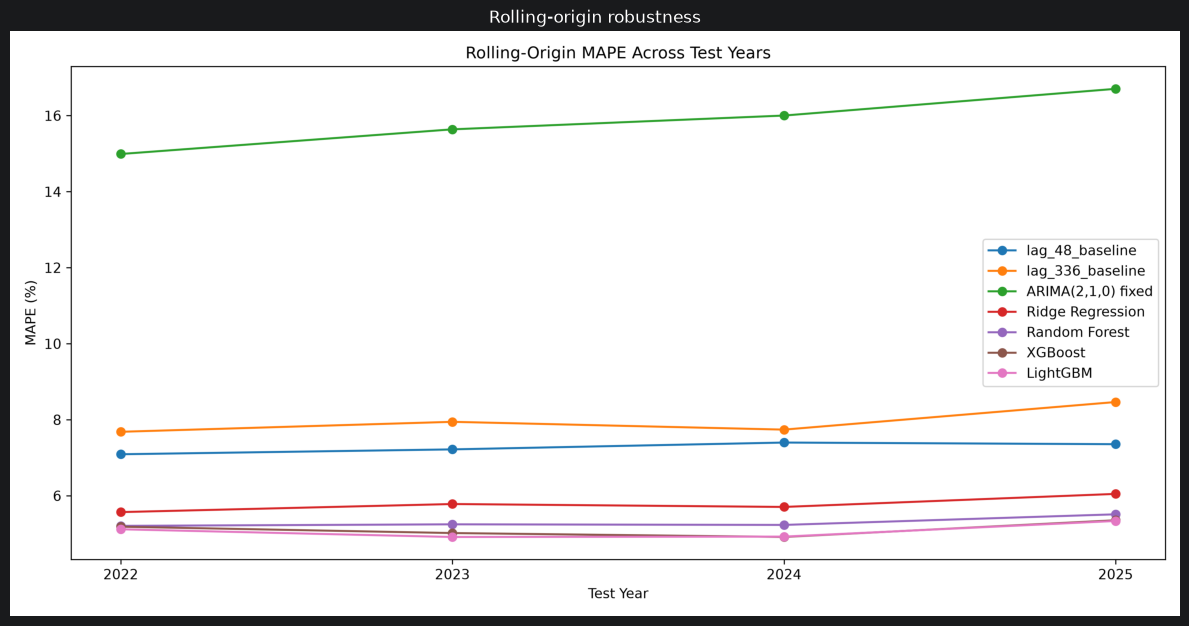

In [10]:
monthly = load_table("monthly_model_performance.csv")
seasonal = load_table("seasonal_model_performance.csv")
rolling = load_table("rolling_origin_yearly_performance.csv")
best_model = ml_results.iloc[0]["Model"]
best_monthly = monthly[monthly["Model"].eq(best_model)].sort_values("MAPE")
seasonal_pivot = seasonal.pivot(index="season", columns="Model", values="MAPE")
rolling_pivot = rolling.pivot(index="Test_Year", columns="Model", values="MAPE")
print(f"Best and worst months for {best_model}")
print_table(pd.concat([best_monthly.head(3), best_monthly.tail(3)]))
print("\nSeasonal MAPE")
print(seasonal_pivot.to_string())
print("\nRolling-origin yearly MAPE")
print(rolling_pivot.to_string())
show_saved_figure("monthly_mape_trend.png", "Monthly robustness")
show_saved_figure("rolling_origin_mape_by_year.png", "Rolling-origin robustness")

### Robustness result and conclusion

**Monthly plot:** LightGBM's MAPE ranged from 4.454% in January to 6.475% in April. Its seasonal MAPE was lowest in winter (4.628%) and highest in spring (6.177%).

**Rolling-year plot:** LightGBM and XGBoost were the two lowest-MAPE models in every test year, although XGBoost ranked first in 2024. Across the four tests, LightGBM's MAPE ranged from 4.916% to 5.337%. The leading pair was fairly stable, but the exact ranking and error level changed over time.

## 11. Sensitivity to excluding 2021 from training

This analysis compares the primary fitting period with an alternative that excludes 2021. The validation and final test years remain unchanged.

In [ ]:
sensitivity = load_table("training_period_sensitivity.csv")
print("Training-period sensitivity results")
print_table(sensitivity[["Model", "Validation_MAPE_Keep_2021", "Validation_MAPE_Remove_2021", "Test_MAPE_Keep_2021", "Test_MAPE_Remove_2021", "Test_MAPE_Delta", "Mean_Daily_MAPE_Delta_CI_Lower", "Mean_Daily_MAPE_Delta_CI_Upper"]])
keep_best = sensitivity.sort_values("Test_MAPE_Keep_2021").iloc[0]
removed_best = sensitivity.sort_values("Test_MAPE_Remove_2021").iloc[0]
print(f"Best model with 2021 retained: {keep_best['Model']} ({keep_best['Test_MAPE_Keep_2021']:.3f}% MAPE)")
print(f"Best model without 2021 training rows: {removed_best['Model']} ({removed_best['Test_MAPE_Remove_2021']:.3f}% MAPE)")
show_saved_figure("training_period_sensitivity_mape.png", "Training-period sensitivity")

## 12. Answer to the research question

The next cell extracts the headline values from the saved result tables.

In [11]:
best_ml = ml_results.iloc[0]
runner_up_ml = ml_results.iloc[1]
best_baseline = baseline_results.iloc[0]
selected_features = selected_ablation.iloc[0]
training_reference_summary = drift_summary[drift_summary["Comparison_Type"].eq("Training reference")]
latest_nd_drift = demand_drift[demand_drift["Comparison"].str.endswith("2025")].iloc[0]
best_improvement = 100 * (best_baseline["MAPE"] - best_ml["MAPE"]) / best_baseline["MAPE"]
frozen_best = fixed_origin[fixed_origin["Model"].eq(best_ml["Model"])].iloc[0]
top_pair = ml_comparisons[(ml_comparisons["Model_A"].eq(best_ml["Model"])) & (ml_comparisons["Model_B"].eq(runner_up_ml["Model"]))].iloc[0]

findings = [
    f"1. Lowest point-estimate final model: {best_ml['Model']} — 2025 MAPE {best_ml['MAPE']:.3f}%.",
    f"2. Best simple baseline: {best_baseline['Model']} — MAPE {best_baseline['MAPE']:.3f}%.",
    f"3. Relative improvement over that baseline: {best_improvement:.2f}%.",
    f"4. Selected feature set: {selected_features['Feature_Set']} — 2023 validation MAPE {selected_features['MAPE']:.3f}%.",
    f"5. Maximum training-reference PSI: {training_reference_summary['Maximum_PSI'].max():.4f}.",
    f"6. 2025 demand mean change from the training reference: {latest_nd_drift['Mean_Change_Percent']:.2f}%.",
    f"7. Frozen {best_ml['Model']} MAPE change from 2024 to 2025: {frozen_best['Relative_MAPE_Change_Percent']:.2f}%.",
    f"8. Top-model paired comparison: {best_ml['Model']} minus {runner_up_ml['Model']} daily MAPE = {top_pair['Mean_Daily_MAPE_Difference_A_Minus_B']:.3f} percentage points, 95% CI [{top_pair['Difference_CI_Lower']:.3f}, {top_pair['Difference_CI_Upper']:.3f}].",
]
print("\n".join(findings))

1. Lowest point-estimate final model: LightGBM — 2025 MAPE 5.337%.
2. Best simple baseline: lag_48_baseline — MAPE 7.357%.
3. Relative improvement over that baseline: 27.46%.
4. Selected feature set: Selected + England/Wales holiday — 2023 validation MAPE 4.916%.
5. Maximum training-reference PSI: 0.0474.
6. 2025 demand mean change from the training reference: -3.37%.
7. Frozen LightGBM MAPE change from 2024 to 2025: 11.72%.
8. Top-model paired comparison: LightGBM minus XGBoost daily MAPE = -0.050 percentage points, 95% CI [-0.169, 0.042].


### Main answer

On the 2025 test set, LightGBM achieved MAE of 1,319 MW, RMSE of 1,803 MW, and MAPE of 5.337%. XGBoost was close, with MAPE of 5.387%. The 95% interval for their paired MAPE difference was [-0.169, 0.042] percentage points. Because this interval includes zero, the results do not show a clear difference between the two models.

Daily persistence had MAPE of 7.357%, so LightGBM reduced MAPE by about 27.5% relative to this baseline. However, LightGBM's monthly MAPE ranged from 4.454% to 6.475%, and frozen nonlinear models had higher MAPE in 2025 than in 2024. In this evaluation, the strongest models forecast demand with about 5.3% MAPE, but the error level was not constant over time.

## 13. Limitations and future work

- **Weather:** Weather was excluded because a consistent archive of forecasts available at each historical forecast origin was not available. Using realised future weather would cause leakage.
- **Forecast interpretation:** Lag values become available as time moves forward. This is not one recursive forecast of the whole year made on 1 January.
- **Model scope:** The ARIMA baseline is non-seasonal. Seasonal ARIMA or models with archived weather forecasts could be tested next.
- **Evidence period:** Stability conclusions are based on 2021–2025 GB national data. Two post-2023 years cannot establish a long-term degradation trend.

### Final conclusion

Both boosting models had lower 2025 MAPE than daily persistence and the non-seasonal ARIMA baseline. The ablation results showed that recent demand and calendar features were both useful. Monthly and frozen-model results showed that forecast error changed over time, supporting regular performance monitoring and consideration of retraining when errors rise.